# Lakonishok, Shleifer, and Vishny (1994) — Table I Replication

This notebook reproduces **Table I: Returns for Decile Portfolios Based on One-Dimensional Classifications by Various Measures of Value** using CRSP, Compustat, and the CRSP/Compustat Merged link table on WRDS.

The target portfolios are **B/M, C/P, E/P, and GS**. The notebook uses the same organization as the momentum replication:

1. portfolio construction;
2. timing;
3. key setup;
4. SQL and data checks;
5. formation variables;
6. annual holding returns;
7. paper-versus-replication diagnostics;
8. exploratory figures.


## 1. Table I construction — step by step

### Step 1 — Measure characteristics at the end of April

For a portfolio formed at the end of April in year \(t\), use prior-year accounting data and end-of-April market equity:

$$
B/M_{i,t}=\frac{BE_{i,t-1}}{ME_{i,t}},
\qquad
C/P_{i,t}=\frac{IB_{i,t-1}+DP_{i,t-1}}{ME_{i,t}},
\qquad
E/P_{i,t}=\frac{IB_{i,t-1}}{ME_{i,t}}.
$$

The paper defines earnings before extraordinary items and cash flow as earnings plus depreciation. C/P and E/P sorts retain only positive ratios.

For sales growth, calculate five annual sales-growth observations, rank firms separately in each relative year, and give greater weight to recent growth:

$$
GS_{i,t}
=
\frac{5Rank_{i,-1}+4Rank_{i,-2}+3Rank_{i,-3}+2Rank_{i,-4}+Rank_{i,-5}}{15}.
$$

### Step 2 — Form annual decile portfolios

At each April formation date, independently sort eligible NYSE/AMEX stocks into ten ascending deciles:

| Signal | Decile 1 | Decile 10 |
|---|---|---|
| B/M, C/P, E/P | Glamour | Value |
| GS | Value: low past sales growth | Glamour: high past sales growth |

All stocks within a decile receive equal initial dollar weights.

### Step 3 — Hold from May through the following April

For an original constituent \(i\), annual holding-year return \(h\) is

$$
R_{i,t}^{(h)}
=
\prod_{m=\text{May}(t+h-1)}^{\text{April}(t+h)}(1+r_{i,m}^{*})-1.
$$

If the stock disappears from CRSP during that holding year, \(r_{i,m}^{*}\) is replaced for the remaining months by the return on the corresponding size-decile portfolio. At the next April, surviving **original constituents** are re-equal-weighted. No new stocks are added and the portfolio is not re-sorted.

### Step 4 — Average across formation cohorts

For each signal, decile, and horizon, first compute the equal-weighted annual return within each formation cohort, then average those cohort returns across all formation years with an available horizon. This gives \(R_1,\ldots,R_5\).

### Step 5 — Construct the reported summary statistics

$$
AR=\frac{1}{5}\sum_{h=1}^{5}R_h,
\qquad
CR5=\prod_{h=1}^{5}(1+R_h)-1.
$$

For size adjustment, assign every stock to its market-cap decile at the end of the previous calendar year, replace the stock's annual return by the annual buy-and-hold return of that size decile, equal-weight those benchmark returns, and subtract the benchmark from the raw portfolio return. `SAAR` is the average of the five annual size-adjusted returns.


## 2. Timeline

### Example: portfolio formed at the end of April 1968

| Relative time | Data or action |
|---|---|
| 1962 | Sales level needed to calculate the earliest of five annual growth rates |
| 1963–1967 | Five sales-growth observations used in GS; 1967 fundamentals used for B/M, C/P, and E/P |
| End-April 1968 | Observe market equity, form ascending deciles, and set equal dollar weights |
| May 1968–April 1969 | Year +1 buy-and-hold return \(R_1\) |
| May 1969–April 1970 | Re-equal-weight surviving original constituents and measure \(R_2\) |
| ... | Continue the same rule |
| May 1972–April 1973 | Year +5 return \(R_5\) |

```text
1962 | 1963 -------- 1967 | Apr-1968 | May-1968 -------- Apr-1969 | ... | Apr-1973
base   five GS growth years  formation       R1                         R5 ends
```

The return sample ends in April 1990. Consequently, later horizons contain fewer formation cohorts:

$$
N(R_1,R_2,R_3,R_4,R_5)=(22,21,20,19,18).
$$

This shrinking-horizon count is a structural validation check and should be verified before comparing returns.


## 3. Key setup

| Item | Baseline used here | Status |
|---|---|---|
| Target table | Table I, Panels A–D | Paper |
| Formation dates | End-April 1968–1989 | Paper |
| Return endpoint | End-April 1990 | Paper |
| Universe | NYSE and AMEX common shares, CRSP share codes 10/11 | Exchange restriction is in the paper; share-code filter is an implementation choice |
| CRSP frequency | Monthly (`crsp.msf`) | Sufficient for annual May–April buy-and-hold returns |
| Compustat frequency | Annual (`comp.funda`) | Paper |
| Earnings / cash flow | `ib`; `ib + dp` | Paper-aligned mapping |
| Book equity | Common equity `ceq` | Paper does not identify a modern Compustat item; sensitivity alternatives are included |
| C/P and E/P eligibility | Positive ratios only | Paper |
| GS | Five annual growth ranks with weights 5,4,3,2,1 | Paper |
| Ranking ties | SAS-style average ranks | Implementation choice |
| Holding / weights | Annual buy-and-hold; equal weight; annual rebalancing of survivors | Paper |
| Disappearance | Size-decile return for the rest of that holding year | Paper |
| Size adjustment | Previous-December market-cap decile | Paper |
| Data vintage | Current CRSP, Compustat, and CCM | Replication limitation |

Only choices that materially affect the replication are shown here; lower-level diagnostics are printed next to the code that creates them.


In [1]:
# ============================================================
# Logic
# 1. Define the sample, formation dates, and implementation choices.
# 2. Create cache/result folders for WRDS reruns.
# 3. Load shared ranking and plotting helpers.
#
# Output:
#   db, constants, load_or_query(), ntile_series(), plot_heatmap()
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wrds

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

FORMATION_START = 1968
FORMATION_END   = 1989
RETURN_END_YEAR = 1989          # May 1989-April 1990 is the last holding year
HOLD_YEARS = [1, 2, 3, 4, 5]

CRSP_START = "1967-12-01"
CRSP_END   = "1990-04-30"
COMP_START = "1962-01-01"
COMP_END   = "1988-12-31"

COMMON_SHARES = [10, 11]
BOOK_EQUITY = "ceq"            # "ceq", "seq", or "ff"
DECILE_METHOD = "sas"          # "sas" or "first"
GS_RANK_MODE = "percentile"    # "percentile" or "raw"

MSF      = "crsp.msf"
MSENAMES = "crsp.msenames"
FUNDA    = "comp.funda"
CCM      = "crsp.ccmxpf_linktable"

CACHE  = Path.home() / "lsv1994_table1_cache_v5"
RESULT = Path.home() / "lsv1994_table1_results_v5"
CACHE.mkdir(parents=True, exist_ok=True)
RESULT.mkdir(parents=True, exist_ok=True)

db = wrds.Connection()


def load_or_query(name, sql, date_cols=None):
    """Read a cached parquet file or execute the SQL once on WRDS."""
    path = CACHE / name

    if path.exists():
        df = pd.read_parquet(path)
        source = "Loaded"
    else:
        df = db.raw_sql(sql, date_cols=date_cols) if date_cols else db.raw_sql(sql)
        df.to_parquet(path, index=False)
        source = "Saved"

    for col in date_cols or []:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col])

    print(f"{source}: {path.name}")
    return df


def ntile_series(s, n=10, method=DECILE_METHOD):
    """Ascending n-tile assignment with an explicit tie convention."""
    out = pd.Series(pd.NA, index=s.index, dtype="Int64")
    valid = s.dropna()

    if len(valid) < n:
        return out

    if method == "sas":
        ranks = valid.rank(method="average")
        groups = np.floor(ranks * n / (len(valid) + 1)).astype(int) + 1
    elif method == "first":
        ranks = valid.rank(method="first")
        groups = pd.qcut(ranks, n, labels=False).astype(int) + 1
    else:
        raise ValueError("method must be 'sas' or 'first'")

    out.loc[valid.index] = np.clip(groups, 1, n)
    return out


def plot_heatmap(data, title, value_fmt=".2f", xlabel="Decile", ylabel="Strategy"):
    arr = data.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(9.0, 4.6))
    image = ax.imshow(arr, aspect="auto")

    ax.set_xticks(np.arange(len(data.columns)), labels=data.columns)
    ax.set_yticks(np.arange(len(data.index)), labels=data.index)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            if np.isfinite(arr[i, j]):
                ax.text(j, i, format(arr[i, j], value_fmt), ha="center", va="center")

    fig.colorbar(image, ax=ax, shrink=0.82)
    plt.tight_layout()
    plt.show()


settings = pd.DataFrame({
    "Setting": ["Formation years", "Holding return endpoint", "Book equity", "GS rank mode", "Cache", "Results"],
    "Value": [f"{FORMATION_START}-{FORMATION_END}", "April 1990", BOOK_EQUITY,
              GS_RANK_MODE, str(CACHE), str(RESULT)],
})

display(settings)


WRDS recommends setting up a .pgpass file.
pgpass file created at C:\Users\phil_prod\AppData\Roaming\postgresql\pgpass.conf
Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done


,Setting,Value
0,Formation years,1968-1989
1,Holding return endpoint,April 1990
2,Book equity,ceq
3,GS rank mode,percentile
4,Cache,C:\Users\phil_prod\lsv1994_table1_cache_v5
5,Results,C:\Users\phil_prod\lsv1994_table1_results_v5


## 4. Data extraction and SQL logic

| Dataset | WRDS table | Native frequency / unit | Role in the replication |
|---|---|---|---|
| Stock returns and market equity | `crsp.msf` | Monthly, one row per PERMNO–month | May–April returns; April and previous-December market equity |
| Security history | `crsp.msenames` | Date-ranged name record | Apply share and exchange codes valid at each CRSP date |
| Fundamentals | `comp.funda` | Annual, one row per GVKEY–fiscal year | Book equity, earnings, depreciation, sales, and five-year sales history |
| Identifier links | `crsp.ccmxpf_linktable` | Date-ranged GVKEY–PERMNO link | Match accounting data to the April CRSP security |

Unlike the momentum paper, this replication does **not** need CRSP daily data. Table I evaluates annual buy-and-hold returns, so monthly CRSP returns contain the required information and substantially reduce the query size. Compustat remains annual; it is never forward-filled into monthly observations.

The CRSP query does not restrict later holding returns to NYSE/AMEX. The universe restriction is imposed at each April formation date, after which the code follows the original constituent even if its later exchange code changes.


In [2]:
# ============================================================
# Logic
# 1. Query monthly CRSP returns and market equity.
# 2. Identify April NYSE/AMEX common-share formation observations.
# 3. Preserve later monthly returns for original constituents.
#
# Output:
#   crsp, april_alive, april_sample
# ============================================================

sql_crsp = f"""
select
    a.permno,
    a.date,
    a.ret,
    a.prc,
    a.shrout,
    b.shrcd,
    b.exchcd
from {MSF} as a
left join {MSENAMES} as b
    on a.permno = b.permno
   and b.namedt <= a.date
   and a.date <= coalesce(b.nameendt, date '9999-12-31')
where a.date between date '{CRSP_START}' and date '{CRSP_END}'
order by a.permno, a.date
"""

crsp = load_or_query(
    "crsp_monthly_196712_199004.parquet",
    sql_crsp,
    date_cols=["date"],
).copy()

for col in ["permno", "ret", "prc", "shrout", "shrcd", "exchcd"]:
    crsp[col] = pd.to_numeric(crsp[col], errors="coerce")

crsp["date"] = pd.to_datetime(crsp["date"])
crsp["year"] = crsp["date"].dt.year
crsp["month"] = crsp["date"].dt.month
crsp["ym"] = crsp["date"].dt.to_period("M")
crsp["me"] = crsp["prc"].abs() * crsp["shrout"] / 1000   # CRSP $000 to Compustat $m
crsp["eligible"] = crsp["shrcd"].isin(COMMON_SHARES) & crsp["exchcd"].isin([1, 2]) & crsp["me"].gt(0)

crsp = (crsp.sort_values(["permno", "date"])
            .drop_duplicates(["permno", "date"], keep="last")
            .reset_index(drop=True))

april_alive = (
    crsp.loc[crsp["month"].eq(4), ["permno", "year"]]
        .drop_duplicates(["permno", "year"], keep="last")
        .rename(columns={"year": "formation_year"})
)
april_sample = (
    crsp.loc[crsp["month"].eq(4) & crsp["eligible"],
             ["permno", "year", "me", "shrcd", "exchcd"]]
        .drop_duplicates(["permno", "year"], keep="last")
        .rename(columns={"year": "formation_year"})
)

crsp_check = pd.DataFrame({
    "Feature": ["Observation unit", "Rows", "PERMNOs", "Months", "Missing RET", "April formation rows"],
    "Value": ["PERMNO-month", f"{len(crsp):,}", f"{crsp['permno'].nunique():,}",
              f"{crsp['ym'].nunique():,}", f"{crsp['ret'].isna().mean():.3%}", f"{len(april_sample):,}"],
})

display(crsp_check)
display(crsp.head(8))

april_count = (april_sample.loc[april_sample["formation_year"].between(FORMATION_START, FORMATION_END)]
                           .groupby("formation_year")["permno"].nunique())
fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.plot(april_count.index, april_count.values, marker="o", linewidth=1.3)
ax.set_title("NYSE/AMEX Common-Share Universe at Each April Formation Date")
ax.set_xlabel("Formation year")
ax.set_ylabel("Number of stocks")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


KeyboardInterrupt: 

In [3]:
# ============================================================
# Logic
# 1. Query annual Compustat fundamentals and CCM link histories.
# 2. Construct book equity, earnings, cash flow, and annual sales growth.
# 3. Keep one accounting observation per GVKEY-calendar year.
#
# Output:
#   comp, links
# ============================================================

sql_comp = f"""
select
    gvkey, datadate, fyear, fyr,
    ceq, seq, pstk, pstkrv, pstkl, txditc,
    ib, dp, sale
from {FUNDA}
where indfmt = 'INDL'
  and datafmt = 'STD'
  and consol = 'C'
  and datadate between date '{COMP_START}' and date '{COMP_END}'
order by gvkey, datadate
"""

sql_ccm = f"""
select
    gvkey,
    lpermno as permno,
    linkdt,
    linkenddt,
    linktype,
    linkprim
from {CCM}
where lpermno is not null
  and linktype in ('LC', 'LU', 'LS')
"""

comp = load_or_query(
    "compustat_annual_1962_1988.parquet",
    sql_comp,
    date_cols=["datadate"],
).copy()

links = load_or_query(
    "ccm_link_history.parquet",
    sql_ccm,
    date_cols=["linkdt", "linkenddt"],
).copy()


# ------------------------------------------------------------
# 1. Standardize numeric types
# ------------------------------------------------------------

# WRDS/parquet may preserve pandas nullable dtypes.
# Store accounting values as ordinary NumPy floats so missing
# observations are represented by np.nan rather than pd.NA.

id_numeric = ["fyear", "fyr"]

value_numeric = [
    "ceq", "seq", "pstk", "pstkrv", "pstkl",
    "txditc", "ib", "dp", "sale",
]

for col in id_numeric:
    comp[col] = (
        pd.to_numeric(comp[col], errors="coerce")
        .astype("Int64")
    )

for col in value_numeric:
    comp[col] = (
        pd.to_numeric(comp[col], errors="coerce")
        .astype("float64")
    )


# ------------------------------------------------------------
# 2. Keep one observation per GVKEY-calendar year
# ------------------------------------------------------------

comp["datadate"] = pd.to_datetime(
    comp["datadate"],
    errors="coerce",
)

comp = comp.dropna(subset=["gvkey", "datadate"]).copy()

comp["acct_year"] = (
    comp["datadate"]
    .dt.year
    .astype(int)
)

comp = (
    comp
    .sort_values(["gvkey", "acct_year", "datadate"])
    .drop_duplicates(
        ["gvkey", "acct_year"],
        keep="last",
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Construct book equity
# ------------------------------------------------------------

preferred = (
    comp["pstkrv"]
    .combine_first(comp["pstkl"])
    .combine_first(comp["pstk"])
)

seq_base = comp["seq"].combine_first(
    comp["ceq"] + comp["pstk"].fillna(0)
)

comp["be_ceq"] = comp["ceq"]

comp["be_seq"] = seq_base

comp["be_ff"] = (
    seq_base
    + comp["txditc"].fillna(0)
    - preferred.fillna(0)
)

book_map = {
    "ceq": "be_ceq",
    "seq": "be_seq",
    "ff": "be_ff",
}

if BOOK_EQUITY not in book_map:
    raise ValueError(
        "BOOK_EQUITY must be 'ceq', 'seq', or 'ff'"
    )

comp["be"] = comp[book_map[BOOK_EQUITY]]


# ------------------------------------------------------------
# 4. Construct earnings and cash flow
# ------------------------------------------------------------

comp["earn"] = comp["ib"]

comp["cf"] = (
    comp["ib"]
    + comp["dp"]
)


# ------------------------------------------------------------
# 5. Construct annual sales growth
# ------------------------------------------------------------

comp = (
    comp
    .sort_values(["gvkey", "acct_year"])
    .copy()
)

g = comp.groupby(
    "gvkey",
    sort=False,
)

comp["lag_sale"] = g["sale"].shift(1)
comp["lag_year"] = g["acct_year"].shift(1)

valid_growth = (
    comp["acct_year"].sub(comp["lag_year"]).eq(1)
    & comp["sale"].gt(0)
    & comp["lag_sale"].gt(0)
).fillna(False)

comp["sales_growth"] = (
    comp["sale"]
    .div(comp["lag_sale"])
    .sub(1)
    .where(valid_growth)
    .astype("float64")
)


# ------------------------------------------------------------
# 6. Standardize CCM link history
# ------------------------------------------------------------

links["permno"] = pd.to_numeric(
    links["permno"],
    errors="coerce",
)

links["linkdt"] = (
    pd.to_datetime(
        links["linkdt"],
        errors="coerce",
    )
    .fillna(pd.Timestamp("1900-01-01"))
)

links["linkenddt"] = (
    pd.to_datetime(
        links["linkenddt"],
        errors="coerce",
    )
    .fillna(pd.Timestamp("2099-12-31"))
)


# ------------------------------------------------------------
# 7. Diagnostic output
# ------------------------------------------------------------

comp_check = pd.DataFrame({
    "Feature": [
        "Observation unit",
        "Rows",
        "GVKEYs",
        "Accounting years",
        "Valid sales growth",
        "CCM links",
    ],
    "Value": [
        "GVKEY-calendar year",
        f"{len(comp):,}",
        f"{comp['gvkey'].nunique():,}",
        f"{comp['acct_year'].nunique():,}",
        f"{comp['sales_growth'].notna().sum():,}",
        f"{len(links):,}",
    ],
})

display(comp_check)

display(
    comp[
        [
            "gvkey",
            "datadate",
            "acct_year",
            "be",
            "earn",
            "cf",
            "sale",
            "lag_sale",
            "sales_growth",
        ]
    ].head(8)
)

Saved: compustat_annual_1962_1988.parquet
Saved: ccm_link_history.parquet


,Feature,Value
0,Observation unit,GVKEY-calendar year
1,Rows,"158,335"
2,GVKEYs,"15,117"
3,Accounting years,27
4,Valid sales growth,"130,663"
5,CCM links,"41,036"


,gvkey,datadate,acct_year,be,earn,cf,sale,lag_sale,sales_growth
0,001000,1962-12-31,1962,0.552000,0.120000,0.160000,1.600000,NaN,NaN
1,001000,1963-12-31,1963,0.553000,0.003000,0.049000,1.457000,1.600000,-0.089375
2,001000,1964-12-31,1964,0.607000,0.039000,0.092000,2.032000,1.457000,0.394647
3,001000,1965-12-31,1965,0.491000,-0.197000,-0.115000,1.688000,2.032000,-0.169291
4,001000,1966-12-31,1966,0.834000,0.201000,0.376000,4.032000,1.688000,1.388626
5,001000,1967-12-31,1967,0.744000,-0.090000,0.108000,3.594000,4.032000,-0.108631
6,001000,1968-12-31,1968,2.571000,0.347000,0.617000,7.400000,3.594000,1.058987
7,001000,1969-12-31,1969,10.210000,1.835000,2.868000,37.392000,7.400000,4.052973


## 5. Formation variables and annual sorts

Previous-year accounting observations are linked to the April security using the CCM link interval valid at formation. The code resolves multiple candidate links before sorting, then verifies that each PERMNO–formation-year appears only once.

GS ranks are calculated within the stock universe available at each formation year and relative lag. The baseline normalizes each annual rank to a percentile before applying the paper's 5,4,3,2,1 weights; this prevents changes in the number of firms with available historical data from mechanically changing the scale of a relative-year rank. A raw-rank sensitivity is available at the end.


Formation rows                    : 45,928
Duplicate PERMNO-formation rows   : 0
Formation years                   : 22
Decile size range                 : 148 to 232


,All,B/M,C/P,E/P,GS
Average N per formation year,"2,088.000000","2,056.000000","1,880.000000","1,858.000000","1,840.000000"


,formation_year,gvkey,permno,me_apr,bm,cp,ep,gs
0,1968,001010,10006,270.864000,0.648573,0.161594,0.110092,0.436468
1,1969,001010,10006,275.703875,0.652922,0.134855,0.078490,0.277391
2,1970,001010,10006,256.665500,0.747502,0.159624,0.085676,0.347833
3,1971,001010,10006,332.629500,0.588255,0.118606,0.055497,0.360079
4,1972,001010,10006,246.268000,0.807689,0.156971,0.064125,0.331582
5,1973,001010,10006,252.970750,0.805603,0.167122,0.075289,0.280730
6,1974,001010,10006,257.876000,0.845030,0.196277,0.099858,0.437645
7,1975,001010,10006,220.875000,1.067332,0.256733,0.130282,0.510403


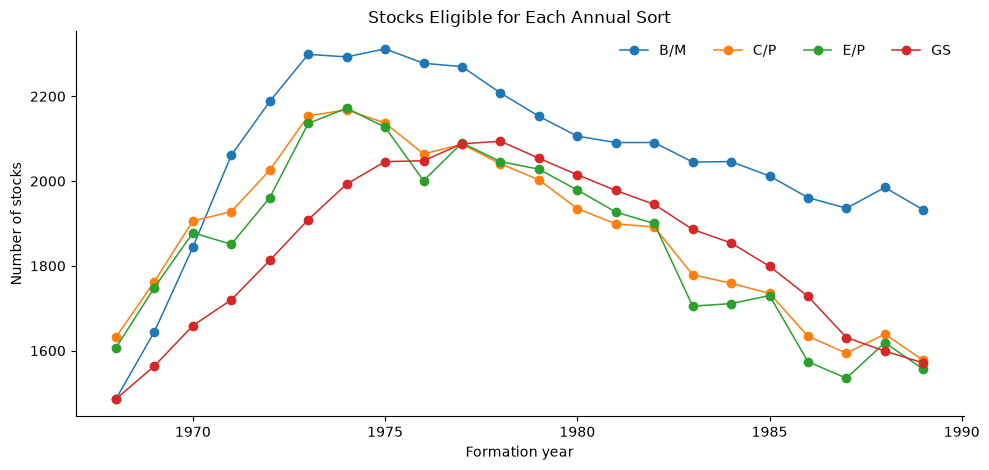

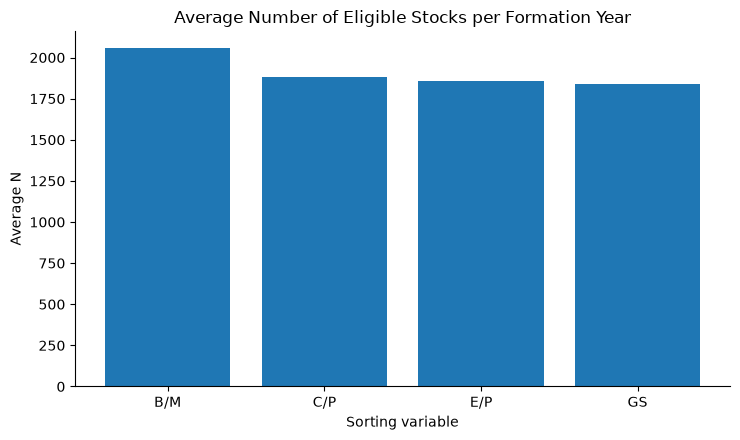

In [4]:
# ============================================================
# Logic
# 1. Link prior-year accounting data to the April CRSP security.
# 2. Construct B/M, C/P, E/P, and the five-year GS score.
# 3. Form independent ascending deciles each April.
#
# Output:
#   formation, constituents, formation_coverage
# ============================================================

acct = comp.copy()
acct["formation_year"] = acct["acct_year"] + 1
acct["formation_date"] = pd.to_datetime(acct["formation_year"].astype(str) + "-04-30")

linked = acct.merge(links, on="gvkey", how="left")
linked = linked.loc[
    linked["permno"].notna()
    & linked["formation_date"].ge(linked["linkdt"])
    & linked["formation_date"].le(linked["linkenddt"])
].copy()

linked["permno"] = linked["permno"].astype(int)
linked["linkprim_rank"] = linked["linkprim"].map({"P": 0, "C": 1}).fillna(9)
linked["linktype_rank"] = linked["linktype"].map({"LC": 0, "LU": 1, "LS": 2}).fillna(9)
linked = (linked.sort_values(
                    ["permno", "formation_year", "linkprim_rank", "linktype_rank", "datadate"],
                    ascending=[True, True, True, True, False])
                .drop_duplicates(["permno", "formation_year"], keep="first"))

formation = (
    linked.loc[linked["formation_year"].between(FORMATION_START, FORMATION_END)]
          .merge(
              april_sample[["permno", "formation_year", "me"]].rename(columns={"me": "me_apr"}),
              on=["permno", "formation_year"], how="inner", validate="one_to_one")
)

formation["bm"] = formation["be"] / formation["me_apr"]
formation["cp"] = formation["cf"] / formation["me_apr"]
formation["ep"] = formation["earn"] / formation["me_apr"]
formation[["bm", "cp", "ep"]] = formation[["bm", "cp", "ep"]].replace([np.inf, -np.inf], np.nan)

base = formation[["gvkey", "permno", "formation_year"]].drop_duplicates().copy()
hist = base.loc[base.index.repeat(5)].reset_index(drop=True)
hist["lag"] = np.tile(np.arange(1, 6), len(base))
hist["acct_year"] = hist["formation_year"] - hist["lag"]
hist = hist.merge(comp[["gvkey", "acct_year", "sales_growth"]],
                  on=["gvkey", "acct_year"], how="left", validate="many_to_one")

rank_pct = GS_RANK_MODE == "percentile"
hist["annual_rank"] = (
    hist.groupby(["formation_year", "lag"])["sales_growth"]
        .rank(method="average", pct=rank_pct)
)
hist["weight"] = 6 - hist["lag"]
hist["weighted_rank"] = hist["annual_rank"] * hist["weight"]

gs = (
    hist.groupby(["gvkey", "permno", "formation_year"], as_index=False)
        .agg(n_gs=("annual_rank", "count"), gs_num=("weighted_rank", "sum"))
)
gs["gs"] = np.where(gs["n_gs"].eq(5), gs["gs_num"] / 15, np.nan)
formation = formation.merge(gs[["gvkey", "permno", "formation_year", "gs"]],
                            on=["gvkey", "permno", "formation_year"], how="left", validate="one_to_one")


def make_constituents(df, strategy, signal, positive=False):
    x = df[["formation_year", "permno", signal]].dropna().copy()
    if positive:
        x = x.loc[x[signal].gt(0)].copy()

    x["decile"] = x.groupby("formation_year", group_keys=False)[signal].transform(
        lambda s: ntile_series(s, 10, DECILE_METHOD)
    )
    x = x.dropna(subset=["decile"]).copy()
    x["decile"] = x["decile"].astype("int8")
    x["strategy"] = strategy
    return x[["formation_year", "permno", "strategy", "decile"]]


constituents = pd.concat([
    make_constituents(formation, "B/M", "bm"),
    make_constituents(formation, "C/P", "cp", positive=True),
    make_constituents(formation, "E/P", "ep", positive=True),
    make_constituents(formation, "GS", "gs"),
], ignore_index=True)

formation_coverage = (
    formation.groupby("formation_year")
             .agg(All=("permno", "nunique"),
                  **{"B/M": ("bm", lambda x: x.notna().sum()),
                     "C/P": ("cp", lambda x: x.gt(0).sum()),
                     "E/P": ("ep", lambda x: x.gt(0).sum()),
                     "GS": ("gs", lambda x: x.notna().sum())})
)

decile_sizes = constituents.groupby(["strategy", "formation_year", "decile"])["permno"].size()

print(f"Formation rows                    : {len(formation):,}")
print(f"Duplicate PERMNO-formation rows   : {formation.duplicated(['permno', 'formation_year']).sum():,}")
print(f"Formation years                   : {formation['formation_year'].nunique():,}")
print(f"Decile size range                 : {decile_sizes.min():,} to {decile_sizes.max():,}")
display(formation_coverage.mean().round(0).to_frame("Average N per formation year").T)
display(formation[["formation_year", "gvkey", "permno", "me_apr", "bm", "cp", "ep", "gs"]].head(8))

fig, ax = plt.subplots(figsize=(10, 4.8))
for col in ["B/M", "C/P", "E/P", "GS"]:
    ax.plot(formation_coverage.index, formation_coverage[col], marker="o", linewidth=1.1, label=col)
ax.set_title("Stocks Eligible for Each Annual Sort")
ax.set_xlabel("Formation year")
ax.set_ylabel("Number of stocks")
ax.legend(frameon=False, ncol=4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

avg_eligible = formation_coverage[["B/M", "C/P", "E/P", "GS"]].mean()
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(avg_eligible.index, avg_eligible.values)
ax.set_title("Average Number of Eligible Stocks per Formation Year")
ax.set_xlabel("Sorting variable")
ax.set_ylabel("Average N")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


## 6. Annual holding returns and size adjustment

CRSP is monthly, but the unit of analysis in Table I is an **annual May–April buy-and-hold return**. The code therefore creates a complete 12-month grid for each stock-year, compounds monthly gross returns, and accepts an annual return only when all twelve monthly returns are available after applying the paper's post-disappearance size-decile replacement.

The size benchmark is built in the same sequence:

1. assign previous-December market-cap deciles;
2. identify the NYSE/AMEX common-share members at the beginning of each May–April holding year;
3. calculate monthly equal-weighted size-decile returns;
4. apply the disappearance rule;
5. compound to an annual size-decile benchmark.


In [5]:
# ============================================================
# Logic
# 1. Assign prior-December size deciles.
# 2. Build monthly and annual size-benchmark returns.
# 3. Follow original portfolio constituents for Years +1 to +5.
# 4. Replace post-disappearance months and compound May-April returns.
#
# Output:
#   annual_stock, needed, stock_grid, size_annual
# ============================================================

# Prior-December size assignment for each May-April holding year.
december = crsp.loc[
    crsp["month"].eq(12) & crsp["eligible"]
    & crsp["year"].between(FORMATION_START - 1, RETURN_END_YEAR - 1),
    ["permno", "year", "me"],
].copy()
december["start_year"] = december["year"] + 1
december["size_decile"] = december.groupby("start_year", group_keys=False)["me"].transform(
    lambda s: ntile_series(s, 10, DECILE_METHOD)
)
december = december.dropna(subset=["size_decile"]).copy()
december["size_decile"] = december["size_decile"].astype("int8")
size_assign = december[["permno", "start_year", "size_decile"]]

# A surviving original constituent only needs a CRSP observation at the next April.
alive = (april_alive.loc[april_alive["formation_year"].between(FORMATION_START, RETURN_END_YEAR),
                         ["permno", "formation_year"]]
                    .rename(columns={"formation_year": "start_year"})
                    .drop_duplicates(["permno", "start_year"]))

# Size benchmark starts with the eligible April universe each year.
size_start = (april_sample.loc[april_sample["formation_year"].between(FORMATION_START, RETURN_END_YEAR),
                              ["permno", "formation_year"]]
                         .rename(columns={"formation_year": "start_year"})
                         .drop_duplicates(["permno", "start_year"]))
size_members = size_start.merge(size_assign, on=["permno", "start_year"], how="inner", validate="one_to_one")

monthly = crsp.loc[
    crsp["ym"].between(pd.Period("1968-05", "M"), pd.Period("1990-04", "M")),
    ["permno", "ym", "ret"],
].copy()
monthly["start_year"] = np.where(monthly["ym"].dt.month >= 5,
                                  monthly["ym"].dt.year,
                                  monthly["ym"].dt.year - 1).astype(int)

size_month = (
    monthly.merge(size_members, on=["permno", "start_year"], how="inner", validate="many_to_one")
           .dropna(subset=["ret"])
           .groupby(["start_year", "size_decile", "ym"], as_index=False)
           .agg(size_ret=("ret", "mean"))
)

months = pd.DataFrame([
    (start_year, month, month_no)
    for start_year in range(FORMATION_START, RETURN_END_YEAR + 1)
    for month_no, month in enumerate(
        pd.period_range(f"{start_year}-05", f"{start_year + 1}-04", freq="M"), start=1)
], columns=["start_year", "ym", "month_no"])

mret = monthly.copy()
mret["row_flag"] = 1


def annualize(stock_year):
    """Construct May-April stock returns with the paper's post-disappearance replacement."""
    grid = (stock_year.merge(months, on="start_year", how="inner", validate="many_to_many")
                      .merge(mret[["permno", "start_year", "ym", "ret", "row_flag"]],
                             on=["permno", "start_year", "ym"], how="left", validate="many_to_one")
                      .merge(size_month, on=["start_year", "size_decile", "ym"],
                             how="left", validate="many_to_one"))

    last = (grid.loc[grid["row_flag"].eq(1)]
                .groupby(["permno", "start_year"], as_index=False)
                .agg(last_obs=("month_no", "max")))
    grid = grid.merge(last, on=["permno", "start_year"], how="left", validate="many_to_one")
    grid["last_obs"] = grid["last_obs"].fillna(0)
    grid["ret_filled"] = grid["ret"]

    post_disappearance = grid["month_no"].gt(grid["last_obs"])
    grid.loc[post_disappearance, "ret_filled"] = grid.loc[post_disappearance, "size_ret"]
    grid["used_size_replacement"] = post_disappearance & grid["ret_filled"].notna()
    grid["gross"] = 1 + grid["ret_filled"]

    out = (grid.groupby(["permno", "start_year", "size_decile"], dropna=False, as_index=False)
               .agg(n_months=("ret_filled", "count"), gross=("gross", "prod"),
                    replacement_months=("used_size_replacement", "sum")))
    out["annual_ret"] = np.where(out["n_months"].eq(12), out["gross"] - 1, np.nan)
    return out, grid


size_stock, _ = annualize(size_members)
size_annual = (size_stock.dropna(subset=["annual_ret"])
                         .groupby(["start_year", "size_decile"], as_index=False)
                         .agg(size_ret_annual=("annual_ret", "mean")))

needed = pd.concat([
    constituents.assign(hold_year=h, start_year=constituents["formation_year"] + h - 1)
    for h in HOLD_YEARS
], ignore_index=True)
needed = needed.loc[needed["start_year"].le(RETURN_END_YEAR)].copy()

stock_year = (needed[["permno", "start_year"]].drop_duplicates()
              .merge(alive, on=["permno", "start_year"], how="inner", validate="one_to_one")
              .merge(size_assign, on=["permno", "start_year"], how="left", validate="one_to_one"))

annual_stock, stock_grid = annualize(stock_year)
annual_stock = annual_stock.merge(size_annual, on=["start_year", "size_decile"],
                                  how="left", validate="many_to_one")
annual_stock["size_adj_ret"] = annual_stock["annual_ret"] - annual_stock["size_ret_annual"]

internal_missing = (stock_grid["month_no"].le(stock_grid["last_obs"])
                    & stock_grid["row_flag"].eq(1) & stock_grid["ret"].isna())

return_check = pd.DataFrame({
    "Feature": ["Needed stock-years", "Valid annual returns", "Valid size-adjusted returns",
                "Internal missing monthly RET", "Stock-years using size replacement"],
    "Value": [f"{len(stock_year):,}", f"{annual_stock['annual_ret'].notna().sum():,}",
              f"{annual_stock['size_adj_ret'].notna().sum():,}", f"{internal_missing.sum():,}",
              f"{annual_stock['replacement_months'].gt(0).sum():,}"],
})
display(return_check)


,Feature,Value
0,Needed stock-years,"46,739"
1,Valid annual returns,"43,862"
2,Valid size-adjusted returns,"43,059"
3,Internal missing monthly RET,"6,381"
4,Stock-years using size replacement,"1,954"


## 7. Table I results: paper, replication, and deviation

For each strategy and decile, the code reports:

- `R1`–`R5`: average annual return at each postformation horizon;
- `AR`: arithmetic average of `R1`–`R5`;
- `CR5`: five-year compounded return using those annual portfolio returns;
- `SAAR`: average annual size-adjusted return.

Each panel is displayed three times: the replication, the published table, and replication minus paper in **percentage points**. A separate extreme-portfolio table focuses on the economically central Value-minus-Glamour spread.


In [6]:
# ============================================================
# Logic
# 1. Aggregate stock returns within formation-year portfolios.
# 2. Average across available formation cohorts for R1-R5.
# 3. Construct AR, CR5, and SAAR.
# 4. Compare every published Table I cell with the replication.
#
# Output:
#   table1, paper_table1, full_compare, extreme_compare, alignment
# ============================================================

portfolio_year = (
    needed.merge(annual_stock[["permno", "start_year", "annual_ret", "size_adj_ret"]],
                 on=["permno", "start_year"], how="left", validate="many_to_one")
          .groupby(["strategy", "formation_year", "decile", "hold_year"], as_index=False)
          .agg(ret=("annual_ret", "mean"), saar=("size_adj_ret", "mean"),
               n_valid=("annual_ret", "count"), n_size_adj=("size_adj_ret", "count"),
               n_constituents=("permno", "nunique"))
)

horizon_check = (portfolio_year.groupby(["strategy", "hold_year"])["formation_year"]
                               .nunique().unstack().reindex(columns=HOLD_YEARS))
expected_horizons = pd.Series([22, 21, 20, 19, 18], index=HOLD_YEARS, name="Paper timing")

display(horizon_check)
display(expected_horizons.to_frame().T)
print("Horizon counts match paper timing:", bool(horizon_check.eq(expected_horizons, axis=1).all().all()))


def table_panel(strategy):
    x = portfolio_year.loc[portfolio_year["strategy"].eq(strategy)]
    raw = (x.groupby(["decile", "hold_year"])["ret"].mean().unstack()
            .reindex(index=range(1, 11), columns=HOLD_YEARS))
    adj = (x.groupby(["decile", "hold_year"])["saar"].mean().unstack()
            .reindex(index=range(1, 11), columns=HOLD_YEARS))

    out = raw.T.copy()
    out.index = [f"R{h}" for h in HOLD_YEARS]
    out.loc["AR"] = raw.mean(axis=1)
    out.loc["CR5"] = (1 + raw).prod(axis=1) - 1
    out.loc["SAAR"] = adj.mean(axis=1)
    out.columns = range(1, 11)
    return out


STATS = ["R1", "R2", "R3", "R4", "R5", "AR", "CR5", "SAAR"]
DECILES = list(range(1, 11))

table1 = {strategy: table_panel(strategy) for strategy in ["B/M", "C/P", "E/P", "GS"]}

paper_table1 = {
    "B/M": pd.DataFrame([
        [0.110,0.117,0.135,0.123,0.131,0.154,0.154,0.170,0.183,0.173],
        [0.079,0.107,0.140,0.145,0.153,0.156,0.169,0.164,0.182,0.188],
        [0.107,0.132,0.155,0.167,0.165,0.172,0.191,0.207,0.196,0.204],
        [0.081,0.133,0.136,0.160,0.170,0.169,0.188,0.204,0.213,0.207],
        [0.088,0.137,0.163,0.175,0.171,0.176,0.216,0.201,0.206,0.215],
        [0.093,0.125,0.146,0.154,0.158,0.166,0.184,0.189,0.196,0.198],
        [0.560,0.802,0.973,1.045,1.082,1.152,1.320,1.375,1.449,1.462],
        [-0.043,-0.020,-0.003,0.004,0.006,0.012,0.024,0.028,0.033,0.035],
    ], index=STATS, columns=DECILES),
    "C/P": pd.DataFrame([
        [0.084,0.124,0.140,0.140,0.153,0.148,0.157,0.178,0.183,0.183],
        [0.067,0.108,0.126,0.153,0.156,0.170,0.177,0.180,0.183,0.190],
        [0.096,0.133,0.153,0.172,0.170,0.191,0.191,0.202,0.193,0.204],
        [0.098,0.111,0.146,0.159,0.166,0.172,0.182,0.192,0.223,0.218],
        [0.108,0.134,0.161,0.162,0.187,0.177,0.191,0.209,0.212,0.208],
        [0.091,0.122,0.145,0.157,0.166,0.171,0.180,0.192,0.199,0.201],
        [0.543,0.779,0.969,1.074,1.158,1.206,1.283,1.406,1.476,1.494],
        [-0.049,-0.025,-0.006,0.005,0.013,0.019,0.025,0.034,0.037,0.039],
    ], index=STATS, columns=DECILES),
    "E/P": pd.DataFrame([
        [0.123,0.125,0.140,0.130,0.135,0.156,0.170,0.180,0.193,0.162],
        [0.101,0.113,0.124,0.143,0.167,0.164,0.180,0.185,0.183,0.174],
        [0.118,0.138,0.157,0.171,0.171,0.191,0.198,0.188,0.188,0.195],
        [0.111,0.124,0.145,0.151,0.157,0.159,0.198,0.199,0.205,0.214],
        [0.119,0.129,0.151,0.167,0.171,0.168,0.196,0.201,0.211,0.207],
        [0.114,0.126,0.143,0.152,0.160,0.167,0.188,0.191,0.196,0.190],
        [0.717,0.808,0.953,1.031,1.102,1.168,1.370,1.393,1.446,1.388],
        [-0.035,-0.024,-0.009,-0.001,0.005,0.013,0.026,0.026,0.029,0.019],
    ], index=STATS, columns=DECILES),
    "GS": pd.DataFrame([
        [0.187,0.183,0.164,0.169,0.162,0.157,0.159,0.164,0.142,0.114],
        [0.181,0.180,0.186,0.169,0.166,0.162,0.152,0.157,0.147,0.131],
        [0.204,0.206,0.194,0.186,0.181,0.180,0.168,0.178,0.157,0.138],
        [0.205,0.193,0.201,0.190,0.181,0.174,0.160,0.153,0.167,0.126],
        [0.197,0.213,0.194,0.199,0.168,0.184,0.185,0.168,0.163,0.125],
        [0.195,0.195,0.188,0.183,0.171,0.171,0.165,0.164,0.155,0.127],
        [1.434,1.435,1.364,1.314,1.205,1.206,1.144,1.136,1.057,0.818],
        [0.022,0.027,0.025,0.024,0.015,0.015,0.008,0.008,0.000,-0.024],
    ], index=STATS, columns=DECILES),
}

compare_rows = []
for strategy in ["B/M", "C/P", "E/P", "GS"]:
    rep = table1[strategy].reindex(index=STATS, columns=DECILES)
    paper = paper_table1[strategy]
    diff_pp = (rep - paper) * 100

    print("\n" + "=" * 98)
    print(f"{strategy} — replication")
    display(rep.round(3))
    print(f"{strategy} — published Table I")
    display(paper.round(3))
    print(f"{strategy} — replication minus paper (percentage points)")
    display(diff_pp.round(2))

    for stat in STATS:
        for decile in DECILES:
            compare_rows.append({
                "strategy": strategy, "stat": stat, "decile": decile,
                "replication": rep.loc[stat, decile], "paper": paper.loc[stat, decile],
                "difference": rep.loc[stat, decile] - paper.loc[stat, decile],
                "difference_bp": (rep.loc[stat, decile] - paper.loc[stat, decile]) * 10_000,
            })

full_compare = pd.DataFrame(compare_rows)

extreme_rows = []
for strategy in ["B/M", "C/P", "E/P", "GS"]:
    glamour, value = (10, 1) if strategy == "GS" else (1, 10)
    for stat in ["AR", "CR5", "SAAR"]:
        rep = table1[strategy]
        paper = paper_table1[strategy]
        extreme_rows.append({
            "strategy": strategy, "stat": stat,
            "rep_glamour": rep.loc[stat, glamour], "paper_glamour": paper.loc[stat, glamour],
            "rep_value": rep.loc[stat, value], "paper_value": paper.loc[stat, value],
            "rep_value_minus_glamour": rep.loc[stat, value] - rep.loc[stat, glamour],
            "paper_value_minus_glamour": paper.loc[stat, value] - paper.loc[stat, glamour],
            "spread_difference_pp": ((rep.loc[stat, value] - rep.loc[stat, glamour])
                                      - (paper.loc[stat, value] - paper.loc[stat, glamour])) * 100,
        })

extreme_compare = pd.DataFrame(extreme_rows)
annual_stats = ["R1", "R2", "R3", "R4", "R5", "AR", "SAAR"]
alignment_rows = []

for strategy in ["B/M", "C/P", "E/P", "GS"]:
    x = full_compare.loc[full_compare["strategy"].eq(strategy)].copy()
    annual = x.loc[x["stat"].isin(annual_stats), "difference"].abs() * 100
    cr5 = x.loc[x["stat"].eq("CR5"), "difference"].abs() * 100
    spread = extreme_compare.loc[
        extreme_compare["strategy"].eq(strategy) & extreme_compare["stat"].isin(["AR", "SAAR"])
    ]

    alignment_rows.append({
        "strategy": strategy,
        "MAE annual-return cells (pp)": annual.mean(),
        "Maximum annual-return difference (pp)": annual.max(),
        "MAE CR5 cells (pp)": cr5.mean(),
        "AR spread difference (pp)": spread.loc[spread["stat"].eq("AR"), "spread_difference_pp"].iloc[0],
        "SAAR spread difference (pp)": spread.loc[spread["stat"].eq("SAAR"), "spread_difference_pp"].iloc[0],
    })

alignment = pd.DataFrame(alignment_rows)

display(extreme_compare.round(4))
display(alignment.round(2))


hold_year,1,2,3,4,5
strategy,,,,,
B/M,22,21,20,19,18
C/P,22,21,20,19,18
E/P,22,21,20,19,18
GS,22,21,20,19,18


,1,2,3,4,5
Paper timing,22,21,20,19,18


Horizon counts match paper timing: True

B/M — replication


,1,2,3,4,5,6,7,8,9,10
R1,0.101000,0.108000,0.114000,0.118000,0.119000,0.142000,0.138000,0.164000,0.165000,0.173000
R2,0.067000,0.092000,0.121000,0.130000,0.141000,0.143000,0.154000,0.151000,0.164000,0.174000
R3,0.090000,0.124000,0.143000,0.158000,0.158000,0.163000,0.174000,0.197000,0.182000,0.197000
R4,0.065000,0.115000,0.118000,0.144000,0.153000,0.149000,0.173000,0.175000,0.196000,0.200000
R5,0.062000,0.110000,0.140000,0.160000,0.155000,0.163000,0.184000,0.185000,0.184000,0.203000
AR,0.077000,0.110000,0.127000,0.142000,0.145000,0.152000,0.164000,0.174000,0.178000,0.189000
CR5,0.450000,0.683000,0.820000,0.941000,0.968000,1.029000,1.140000,1.234000,1.271000,1.379000
SAAR,-0.047000,-0.023000,-0.008000,0.006000,0.008000,0.012000,0.020000,0.025000,0.028000,0.038000


B/M — published Table I


...

,1,2,3,4,5,6,7,8,9,10
R1,0.187000,0.183000,0.164000,0.169000,0.162000,0.157000,0.159000,0.164000,0.142000,0.114000
R2,0.181000,0.180000,0.186000,0.169000,0.166000,0.162000,0.152000,0.157000,0.147000,0.131000
R3,0.204000,0.206000,0.194000,0.186000,0.181000,0.180000,0.168000,0.178000,0.157000,0.138000
R4,0.205000,0.193000,0.201000,0.190000,0.181000,0.174000,0.160000,0.153000,0.167000,0.126000
R5,0.197000,0.213000,0.194000,0.199000,0.168000,0.184000,0.185000,0.168000,0.163000,0.125000
AR,0.195000,0.195000,0.188000,0.183000,0.171000,0.171000,0.165000,0.164000,0.155000,0.127000
CR5,1.434000,1.435000,1.364000,1.314000,1.205000,1.206000,1.144000,1.136000,1.057000,0.818000
SAAR,0.022000,0.027000,0.025000,0.024000,0.015000,0.015000,0.008000,0.008000,0.000000,-0.024000


GS — replication minus paper (percentage points)


,1,2,3,4,5,6,7,8,9,10
R1,-1.750000,-2.390000,-1.060000,-2.380000,-1.830000,-0.680000,-2.200000,-3.470000,-3.800000,-1.680000
R2,-1.980000,-2.650000,-3.170000,-0.790000,-2.310000,-2.440000,-2.810000,-3.410000,-2.200000,-3.310000
R3,-2.440000,-1.320000,-1.700000,-0.900000,-1.790000,-2.510000,-0.120000,-3.240000,-1.690000,-1.740000
R4,-3.050000,-2.700000,-3.020000,-1.850000,-4.040000,-3.030000,0.410000,-2.260000,-3.590000,-1.560000
R5,-1.970000,-2.850000,-3.310000,-2.820000,0.010000,-3.970000,-2.720000,-3.090000,-2.490000,-1.790000
AR,-2.260000,-2.380000,-2.470000,-1.790000,-1.930000,-2.490000,-1.510000,-3.090000,-2.730000,-2.040000
CR5,-21.880000,-23.230000,-23.390000,-16.740000,-17.950000,-22.820000,-13.450000,-26.870000,-23.420000,-15.870000
SAAR,-0.160000,-0.250000,-0.510000,0.150000,0.060000,-0.560000,0.370000,-1.060000,-0.750000,-0.410000


,strategy,stat,rep_glamour,paper_glamour,rep_value,paper_value,rep_value_minus_glamour,paper_value_minus_glamour,spread_difference_pp
0,B/M,AR,0.077200,0.093000,0.189400,0.198000,0.112200,0.105000,0.716300
1,B/M,CR5,0.449600,0.560000,1.379200,1.462000,0.929600,0.902000,2.759100
2,B/M,SAAR,-0.046700,-0.043000,0.037800,0.035000,0.084500,0.078000,0.652400
3,C/P,AR,0.071900,0.091000,0.193400,0.201000,0.121500,0.110000,1.146100
4,C/P,CR5,0.414500,0.543000,1.419400,1.494000,1.004900,0.951000,5.393500
5,C/P,SAAR,-0.054400,-0.049000,0.043200,0.039000,0.097600,0.088000,0.955800
6,E/P,AR,0.095000,0.114000,0.178300,0.190000,0.083300,0.076000,0.729900
7,E/P,CR5,0.573600,0.717000,1.269300,1.388000,0.695700,0.671000,2.470600
8,E/P,SAAR,-0.038200,-0.035000,0.025400,0.019000,0.063600,0.054000,0.960800
9,GS,AR,0.106600,0.127000,0.172400,0.195000,0.065800,0.068000,-0.219100


,strategy,MAE annual-return cells (pp),Maximum annual-return difference (pp),MAE CR5 cells (pp),AR spread difference (pp),SAAR spread difference (pp)
0,B/M,1.310000,3.230000,13.050000,0.720000,0.650000
1,C/P,1.340000,2.840000,13.440000,1.150000,0.960000
2,E/P,1.450000,3.200000,14.650000,0.730000,0.960000
3,GS,2.020000,4.040000,20.560000,-0.220000,0.260000


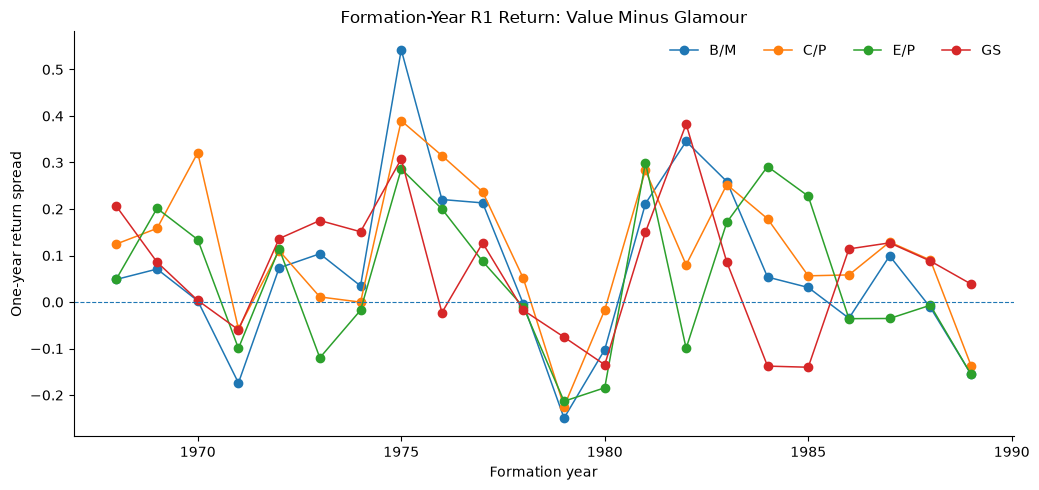

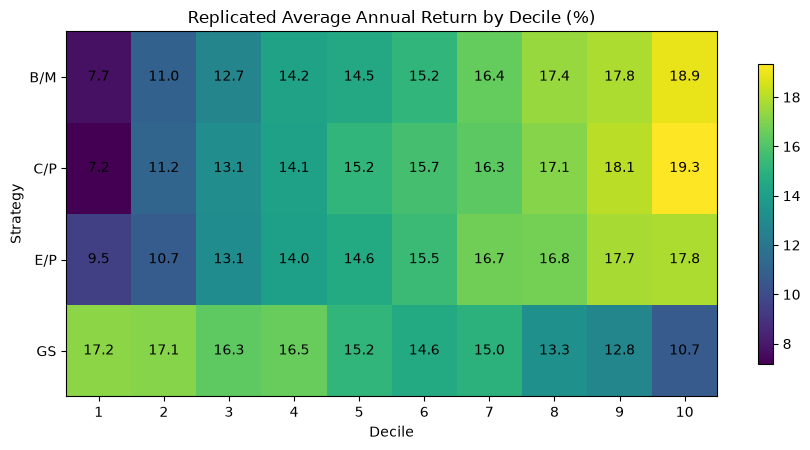

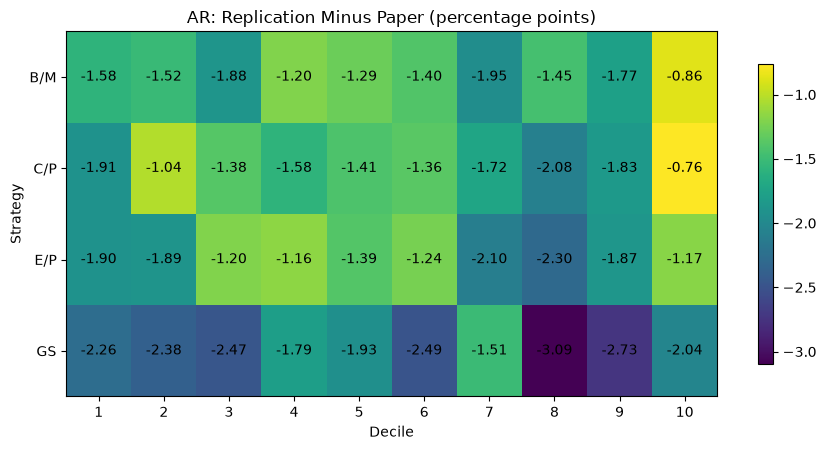

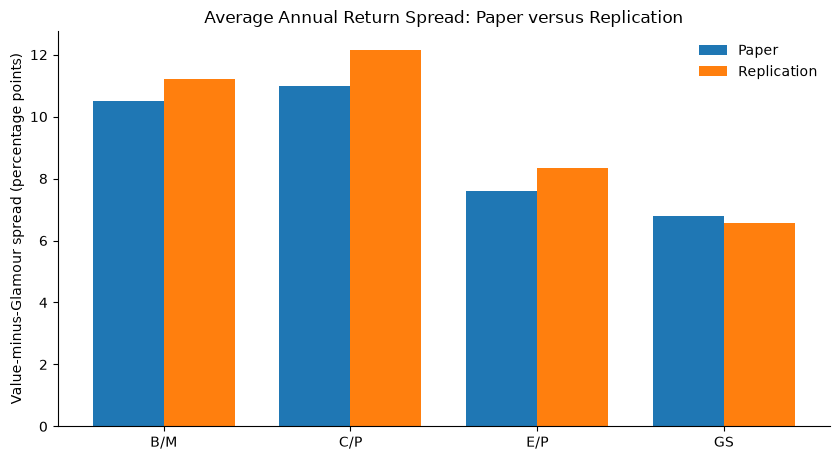

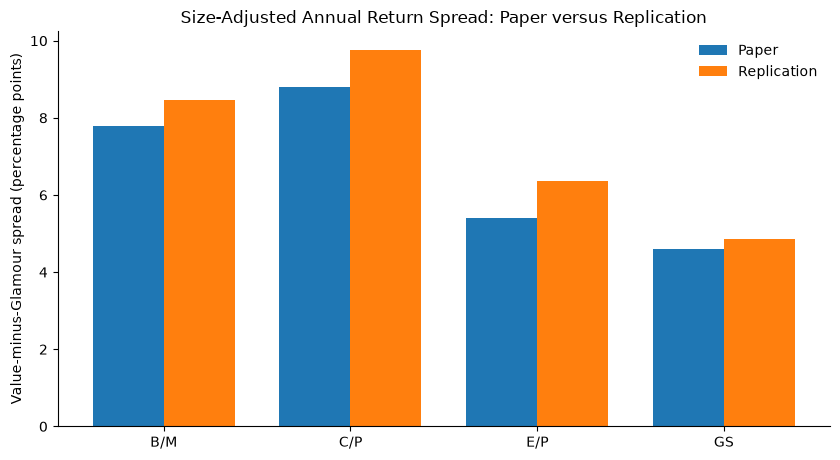

In [7]:
# ============================================================
# Logic
# 1. Plot formation-year Value-minus-Glamour R1 returns.
# 2. Plot AR levels and AR deviations across all deciles.
# 3. Compare published and replicated extreme-portfolio spreads.
# ============================================================

# Formation-year time series of the first annual holding-period spread.
r1 = portfolio_year.loc[portfolio_year["hold_year"].eq(1)]
r1_spread = {}

for strategy in ["B/M", "C/P", "E/P", "GS"]:
    pivot = (r1.loc[r1["strategy"].eq(strategy)]
               .pivot(index="formation_year", columns="decile", values="ret"))
    glamour, value = (10, 1) if strategy == "GS" else (1, 10)
    r1_spread[strategy] = pivot[value] - pivot[glamour]

r1_spread = pd.DataFrame(r1_spread)

fig, ax = plt.subplots(figsize=(10.5, 5.0))
for strategy in r1_spread.columns:
    ax.plot(r1_spread.index, r1_spread[strategy], marker="o", linewidth=1.1, label=strategy)
ax.axhline(0, linewidth=0.8, linestyle="--")
ax.set_title("Formation-Year R1 Return: Value Minus Glamour")
ax.set_xlabel("Formation year")
ax.set_ylabel("One-year return spread")
ax.legend(frameon=False, ncol=4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

ar_rep = pd.DataFrame({s: table1[s].loc["AR"] for s in ["B/M", "C/P", "E/P", "GS"]}).T
ar_paper = pd.DataFrame({s: paper_table1[s].loc["AR"] for s in ["B/M", "C/P", "E/P", "GS"]}).T
plot_heatmap(ar_rep * 100, "Replicated Average Annual Return by Decile (%)", value_fmt=".1f")
plot_heatmap((ar_rep - ar_paper) * 100, "AR: Replication Minus Paper (percentage points)", value_fmt=".2f")


def spread_frame(stat):
    x = extreme_compare.loc[extreme_compare["stat"].eq(stat)].copy()
    return x.set_index("strategy")[["paper_value_minus_glamour", "rep_value_minus_glamour"]]


def plot_spread_comparison(stat, title, scale=100):
    x = spread_frame(stat)
    pos = np.arange(len(x))
    width = 0.38

    fig, ax = plt.subplots(figsize=(8.5, 4.7))
    ax.bar(pos - width / 2, x["paper_value_minus_glamour"] * scale, width, label="Paper")
    ax.bar(pos + width / 2, x["rep_value_minus_glamour"] * scale, width, label="Replication")
    ax.set_xticks(pos, labels=x.index)
    ax.set_ylabel("Value-minus-Glamour spread (percentage points)")
    ax.set_title(title)
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()


plot_spread_comparison("AR", "Average Annual Return Spread: Paper versus Replication")
plot_spread_comparison("SAAR", "Size-Adjusted Annual Return Spread: Paper versus Replication")


## 8. Interpretation and replication limits

### What Table I establishes

Across the published one-dimensional sorts, value portfolios outperform glamour portfolios. The annual Value-minus-Glamour spreads are **10.5 percentage points for B/M**, **11.0 for C/P**, **7.6 for E/P**, and **6.8 for GS**. The corresponding size-adjusted spreads remain economically large. Table I is therefore the first return-pattern result in the paper; the extrapolation and risk interpretations are evaluated in later tables rather than inferred from Table I alone.

### Why a modern WRDS replication may differ

1. **Compustat vintage and coverage.** The authors used the database, including the research file, available in the early 1990s.
2. **Book equity mapping.** The paper says book value of equity but does not identify a modern Compustat item.
3. **CCM links.** Modern historical link records and link priorities differ from hand-built mappings available at the time.
4. **CRSP revisions and delistings.** Historical returns and security histories have been revised.
5. **Ranking conventions.** The paper does not report the treatment of ties or the normalization of GS ranks.
6. **Post-disappearance implementation.** The economic rule is explicit, but the original monthly program is unavailable.

The full comparison object retains every Table I cell, while the extreme-portfolio summary isolates the value premium that is central to the paper's argument.


In [8]:
# ============================================================
# Logic
# Save paper tables, replication tables, deviations, and audit datasets.
# ============================================================

for strategy in ["B/M", "C/P", "E/P", "GS"]:
    tag = strategy.replace("/", "")
    table1[strategy].to_csv(RESULT / f"table1_{tag}_replication.csv")
    paper_table1[strategy].to_csv(RESULT / f"table1_{tag}_paper.csv")
    ((table1[strategy] - paper_table1[strategy]) * 100).to_csv(
        RESULT / f"table1_{tag}_difference_percentage_points.csv"
    )

formation.to_parquet(RESULT / "formation_panel.parquet", index=False)
constituents.to_parquet(RESULT / "portfolio_constituents.parquet", index=False)
portfolio_year.to_parquet(RESULT / "portfolio_year_returns.parquet", index=False)
full_compare.to_csv(RESULT / "table1_full_comparison.csv", index=False)
extreme_compare.to_csv(RESULT / "table1_extreme_portfolio_comparison.csv", index=False)
alignment.to_csv(RESULT / "table1_alignment_summary.csv", index=False)
r1_spread.to_csv(RESULT / "r1_value_minus_glamour_by_formation_year.csv")

print("Saved to:", RESULT)


Saved to: C:\Users\phil_prod\lsv1994_table1_results_v5


## 9. Sensitivity checks

Keep the main specification fixed, then vary one feature at a time:

- `BOOK_EQUITY = "ceq"`, `"seq"`, or `"ff"`;
- `DECILE_METHOD = "sas"` versus `"first"`;
- `GS_RANK_MODE = "percentile"` versus `"raw"`;
- common shares only versus the broader NYSE/AMEX security universe;
- alternative CCM link-type restrictions;
- a separate modern CRSP delisting-return adjustment.

For each sensitivity, compare the full-cell mean absolute error and the AR/SAAR Value-minus-Glamour spreads. Do not select the main specification only because it happens to match one published extreme cell.
